# **Tarea 1 – Analítica de Datos (MACI 2026)**

**Alumno:** Keyden Urbina

**Mercado de celulares en Chile (solotodo.cl) y modelo de rango de precios**

Las cifras de las interpretaciones corresponden a la extracción del **08-11-2026 11:55** (web scraping del HTML, columna `fecha_extraccion`).

## Preguntas de exploración

### Pregunta A: TOP 3 - Marcas con el precio más alto
Para las 3 marcas con el precio promedio más alto (considerando el precio de un mismo modelo en distintas tiendas), presenta sus estadísticas descriptivas (media, desviación estándar, mínimo, máximo, cuartiles) y haz una pequeña interpretación. Utiliza solo los precios en ofertas de los celulares no reacondicionados.

In [1]:
# Librerías que usa este notebook
import pandas as pd                    # tablas
import matplotlib.pyplot as plt        # gráfico de la pregunta c
from pathlib import Path               # rutas de carpetas
pd.set_option("display.max_columns", None)   # muestra todas las columnas de las tablas (sin "…")
pd.set_option("display.width", 200)

# Ruta a data/processed: la busca subiendo desde donde se ejecuta (sirve desde notebooks/ o desde la raíz)
PROC = next(p / "data" / "processed" for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "data" / "processed").is_dir())

clean = pd.read_csv(PROC / "data_processed.csv")      # datos limpios del notebook 02
print(clean.shape, "← cargado desde", PROC / "data_processed.csv")

(1006, 17) ← cargado desde /Users/keydenurbina/Desktop/github/Proyecto Web Scraping/data/processed/data_processed.csv


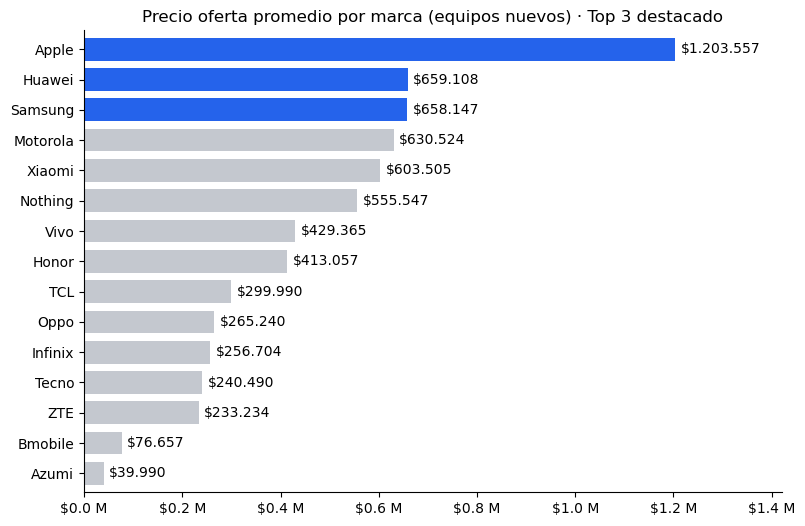

In [2]:
nuevos = clean[clean.es_nuevo == 1]                                        # solo equipos nuevos (con oferta liberada)
top3 = nuevos.groupby("marca").precio_oferta.mean().nlargest(3).index      # 3 marcas con mayor precio promedio

prom = nuevos.groupby("marca").precio_oferta.mean().sort_values()          # promedio por marca, de menor a mayor
colores = ["#2563eb" if m in top3 else "#c4c8cf" for m in prom.index]      # top 3 en azul, el resto en gris

ax = prom.plot.barh(color=colores, figsize=(9, 6), width=0.75)             # barras horizontales: nombres legibles
etiquetas = [f"${v:,.0f}".replace(",", ".") for v in prom]                 # monto en todas las barras: 645953 → $645.953
ax.bar_label(ax.containers[0], labels=etiquetas, padding=4)                # escribe cada monto al final de su barra
ax.set_xlim(right=prom.max() * 1.18)                                       # 18 % de espacio extra para que el monto mayor no se corte
ax.set(title="Precio oferta promedio por marca (equipos nuevos) · Top 3 destacado", xlabel="", ylabel="")
ax.xaxis.set_major_formatter(lambda x, _: f"${x/1e6:.1f} M")               # eje en millones: 1.200.000 → $1.2 M
ax.spines[["top", "right"]].set_visible(False)                             # quita bordes que no aportan
plt.show()

**Interpretación del ranking:**

- **Apple lidera sola:** su promedio de **\$1.203.557** es 1,83 veces el de Huawei (\$659.108), la segunda.

- **Huawei y Samsung están prácticamente empatados:** Huawei supera a Samsung (\$658.147) por solo **\$961 (0,1 %)**. El orden entre ambas depende de unas pocas ofertas: Huawei tiene 34 precios de 12 modelos, y Samsung, 184 de 23.

- **Motorola es cuarta** (\$630.524), \$27.623 (4,2 %) bajo Samsung. Le sigue Xiaomi (\$603.505).

- **Escalones de precio:** Apple supera el millón. Huawei, Samsung, Motorola y Xiaomi están entre \$600 y \$660 mil, y Nothing, en \$556 mil. Vivo y Honor rondan los \$410–430 mil; TCL, Oppo, Infinix, Tecno y ZTE se agrupan entre \$233 y \$300 mil, y Bmobile y Azumi quedan bajo los \$80 mil.

- **Ojo con marcas de pocos datos:** TCL y Azumi tienen un solo precio de un solo modelo nuevo; Bmobile, 3 precios, y Nothing, 7 precios de 4 modelos.

In [3]:
nuevos = clean[clean.es_nuevo == 1]                                        # solo equipos nuevos (con oferta liberada)
top3 = nuevos.groupby("marca").precio_oferta.mean().nlargest(3).index      # 3 marcas con mayor precio promedio
t3 = nuevos[nuevos.marca.isin(top3)]                                       # filas de esas 3 marcas
t3.groupby("marca").precio_oferta.describe().loc[top3].round(0)            # media, desv., mín., cuartiles y máx.

,count,mean,std,min,25%,50%,75%,max
marca,,,,,,,,
Apple,86.0,1203557.0,414705.0,479990.0,821240.0,1184990.0,1529990.0,2499990.0
Huawei,34.0,659108.0,426674.0,159990.0,379990.0,484990.0,874990.0,1699990.0
Samsung,184.0,658147.0,464234.0,119990.0,249990.0,563994.0,956240.0,2089990.0


**Interpretación de la tabla:**

- **Nivel de precio:** la media de Apple es 1,83 veces la de Huawei y la de Samsung, que están separadas por \$961.

- **Apple está en otro tramo:** su mediana (\$1.184.990) supera el tercer cuartil de Huawei (\$874.990) y de Samsung (\$956.240). O sea, la mitad de los precios de Apple está sobre el 75 % de los precios de las otras dos. Su precio nuevo más bajo es \$479.990 (iPhone 14 en TecTec).

- **Dispersión:** en relación con su media, Apple es la más concentrada (CV 34%), frente a Huawei (65%) y Samsung (71%). En pesos, los rangos intercuartiles de Apple (\$708.750) y Samsung (\$706.250) son parecidos, pero el de Apple es angosto en relación con su nivel de precio. Samsung tiene el rango más amplio: de \$119.990 a \$2.089.990 (17 veces).

- **Asimetría:** en las tres marcas la media supera a la mediana, pero en distinta medida: Huawei +36%, Samsung +17% y Apple solo +2%. En Huawei y Samsung, pocos equipos muy caros (plegables, Ultra, Mate y Pura) inflan el promedio; en ellas la mediana representa mejor el precio típico. En Apple, media y mediana casi coinciden.

- **Tamaño de muestra:** Samsung es la cifra más robusta, con 184 precios de 23 modelos. Apple tiene 86 precios de 13 modelos y Huawei, 34 de 12.

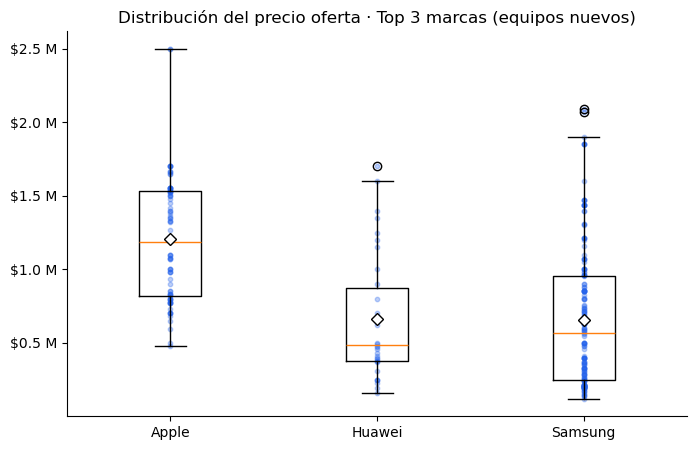

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot([t3[t3.marca == m].precio_oferta for m in top3], tick_labels=top3, showmeans=True,   # una caja por marca
           meanprops=dict(marker="D", markerfacecolor="white", markeredgecolor="black"))         # ◇ = media
for i, m in enumerate(top3, 1):                                            # puntos: cada precio real, semitransparente
    ax.scatter([i] * (t3.marca == m).sum(), t3[t3.marca == m].precio_oferta, s=10, alpha=0.3, color="#2563eb")
ax.yaxis.set_major_formatter(lambda y, _: f"${y/1e6:.1f} M")               # eje en millones
ax.set(title="Distribución del precio oferta · Top 3 marcas (equipos nuevos)")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

**Interpretación del boxplot:**

- **Apple está en otro nivel:** su caja (\$821 mil – \$1,53 M) empieza más o menos donde terminan las de Huawei (\$875 mil) y Samsung (\$956 mil).

- **Apple no tiene valores atípicos:** su precio más alto, el iPhone Duo en Apple Store (\$2.499.990), queda dentro de su rango esperado (límite \$2,59 M).

- **Samsung reparte sus precios en todo el espectro:** su caja va de \$250 mil a \$956 mil, con mediana de \$564 mil. La de Huawei es más angosta (\$380–875 mil), con mediana de \$485 mil. Samsung baja más por su línea Galaxy A de entrada y sube más por sus S y Fold.

- **Valores atípicos:**
  - **Samsung tiene 2**, sobre \$2,02 M: el Z Fold7 en Travel Tienda (\$2.069.990) y el S25 Ultra en PC Factory (\$2.089.990). Ese mismo S25 Ultra se vende en \$799.990 en Lider (mediana de sus 13 precios: \$1.310.095): el atípico refleja la **dispersión entre tiendas**, no un producto distinto.
  - **Huawei tiene 1:** el Mate 80 Pro en Huawei Shop (\$1.699.990), sobre su límite de \$1,62 M. El mismo equipo aparece desde \$999.990.

- En las tres marcas el rombo (media) queda sobre la línea naranja (mediana), lo que confirma la asimetría de la tabla. En Apple casi se tocan.

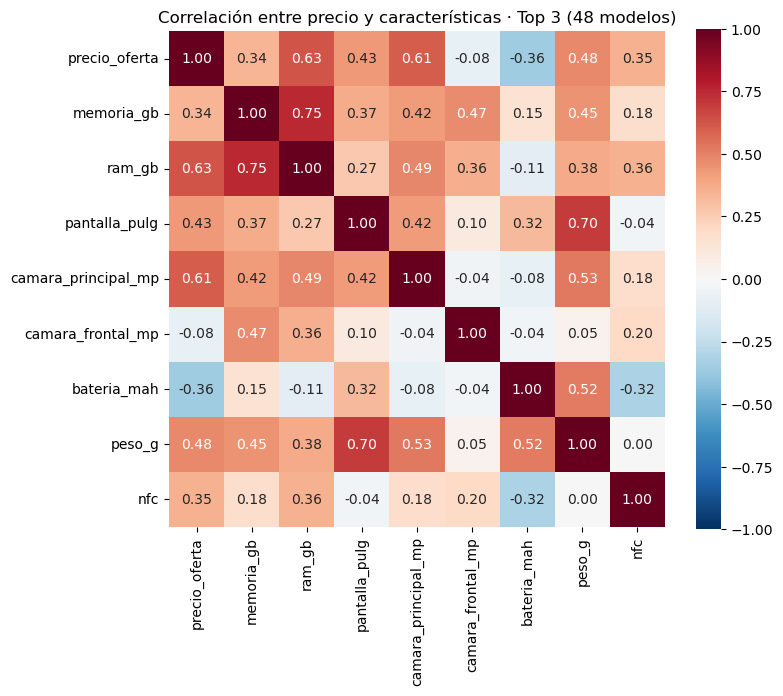

In [5]:
import seaborn as sns
cols = ["precio_oferta", "memoria_gb", "ram_gb", "pantalla_pulg", "camara_principal_mp",
        "camara_frontal_mp", "bateria_mah", "peso_g", "nfc"]
modelos = t3.groupby("nombre")[cols].median()          # 1 fila por modelo: precio = mediana entre tiendas
plt.figure(figsize=(8, 6.5))
sns.heatmap(modelos.corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True)   # rojo +, azul −
plt.title(f"Correlación entre precio y características · Top 3 ({len(modelos)} modelos)")
plt.show()

**Interpretación del mapa de correlación (48 modelos, uno por fila):**

- **Las características que más se asocian al precio son la RAM (0,63) y la cámara principal (0,61)**, seguidas del peso (0,48), la pantalla (0,43), el NFC (0,35) y la memoria (0,34).

- **La memoria se asocia poco (0,34)** porque varía poco en este grupo: ningún modelo del top 3 pasa de 512 GB, y Apple, la marca más cara, llega solo a 256 GB en las variantes extraídas.

- **La batería (−0,36) no significa que más mAh abarate el equipo.** Se suman dos efectos:
  - Mezclar marcas: Apple, la más cara, tiene baterías más chicas (mediana 3.997 mAh contra 5.000 de Samsung y 5.335 de Huawei).
  - Dentro de Samsung y Huawei, la gama de entrada trae baterías grandes (ver la tabla por marca).

- **NFC (0,35):** 6 de los 7 modelos sin NFC son de entrada (5 Galaxy A de \$186–240 mil y el Huawei Nova Y74). La excepción es el Huawei Mate 80 Pro.

- **La cámara frontal (−0,08) no se relaciona con el precio.**

- **Las características se mueven juntas:** memoria–RAM (0,75), pantalla–peso (0,70), cámara–peso (0,53) y batería–peso (0,52). Un equipo de gama alta trae todo "más grande" a la vez. Esto importa para el Objetivo 2: varias variables cuentan la misma historia, así que el modelo se reparte la importancia entre ellas.

- **Ojo:** la correlación de Pearson solo mide relaciones lineales, no prueba causalidad y aquí se calcula sobre 48 modelos. A 5 modelos les falta la batería ("N/A"); su correlación usa los 43 restantes.

In [6]:
pd.DataFrame({m: t3[t3.marca == m].groupby("nombre")[cols].median().corr().precio_oferta for m in top3}
            ).drop("precio_oferta").round(2)               # cada columna: una marca; cada fila: una característica

,Apple,Huawei,Samsung
memoria_gb,0.66,0.61,0.70
ram_gb,0.74,0.71,0.84
pantalla_pulg,0.90,0.67,0.48
camara_principal_mp,0.68,0.92,0.70
camara_frontal_mp,0.29,-0.30,0.51
bateria_mah,0.76,-0.40,-0.41
peso_g,0.90,0.73,0.28
nfc,NaN,-0.05,0.51


**Interpretación: en cada marca, el precio se asocia a características distintas:**

- **Apple:** en esta muestra, los iPhone más grandes tienden a ser más caros. Pantalla y peso correlacionan 0,90 con el precio; la batería, 0,76, y la RAM, 0,74. El precio va del iPhone 14 (6,1", \$479.990) al iPhone Duo (7,6", \$2.499.990). La batería correlaciona positivamente porque los equipos grandes traen baterías grandes. El NFC aparece vacío (NaN) porque todos los iPhone lo tienen: una variable que no cambia no puede correlacionar.

- **Huawei:** los modelos con más megapíxeles en la cámara principal tienden a ser más caros (0,92). Va de 50 MP en el Nova Y73 (\$174.990) a 152,5 MP sumados en el Pura 80 Ultra (\$1.374.990).

- **Samsung:** los modelos con más RAM tienden a ser más caros (0,84). Va de 4 GB en los Galaxy A07 y A17 (\$186–207 mil) a 12 GB en las líneas S y Fold. La cámara y la memoria (0,70 cada una) también se asocian, y el NFC (0,51) separa a algunos Galaxy A de entrada, los únicos sin NFC.

- **En Samsung y Huawei, la batería se asocia negativamente al precio** (−0,41 y −0,40): los equipos baratos traen las baterías más grandes, como el Nova Y73 (6.620 mAh, \$174.990).

- **Ojo:** estas son asociaciones, no causas. En cada marca, la RAM, la cámara y el tamaño suben junto con la gama, el procesador y los materiales, y la correlación no permite separar el efecto de cada característica. Además, con 12 a 23 modelos por marca, un solo equipo puede mover el coeficiente.

#### Conclusión de la pregunta A
- **Apple es la marca más cara en toda su distribución,** no solo en promedio: su mediana (\$1.184.990) supera el tercer cuartil de Huawei y de Samsung, y casi no tiene asimetría (media y mediana difieren 2 %).

- **Huawei y Samsung empatan en promedio (0,1 % de diferencia), pero con perfiles distintos:** Samsung tiene un precio típico más alto (mediana \$563.994 contra \$484.990) y un rango más amplio. El promedio de Huawei se apoya en pocos modelos caros (Mate y Pura).

- **El tercer lugar no es robusto:** Samsung queda tercera por \$961. Con otra extracción, Huawei y Samsung podrían intercambiar posiciones.

**Lectura para la emprendedora:** fuera de Apple, el precio típico de las marcas caras está entre \$485 y \$565 mil. En esta muestra, los modelos más caros tienden a tener más RAM, más megapíxeles y pantallas más grandes, y en la gama de entrada son frecuentes las baterías grandes. Es una asociación: no prueba que agregar esas características permita cobrar más, porque suben junto con la gama completa del equipo. Sí indica con qué características compiten los equipos de cada tramo de precio.

### Pregunta B: Ripley vs. Falabella vs. Paris
Filtra tu base de datos para incluir únicamente los celulares vendidos por las tiendas Ripley, Falabella y Paris. Compara el precio promedio de los celulares en cada una de estas tres tiendas y determina cuál es, en promedio, la más cara y cuál la más barata. Utiliza solo los precios en ofertas de los celulares no reacondicionados. Haz una pequeña interpretación.

Se usan los nombres exactos "Ripley", "Falabella" y "Paris". "Ripley Marketplace" y "Falabella Marketplace" quedan fuera por ser vendedores terceros.

               mean    median  count
tienda                              
Paris      560042.0  399990.0     58
Ripley     566200.0  404990.0     62
Falabella  583329.0  419990.0     56

27 modelos en común | veces que cada tienda tiene el menor precio: {'Falabella': 10, 'Paris': 10, 'Ripley': 10}


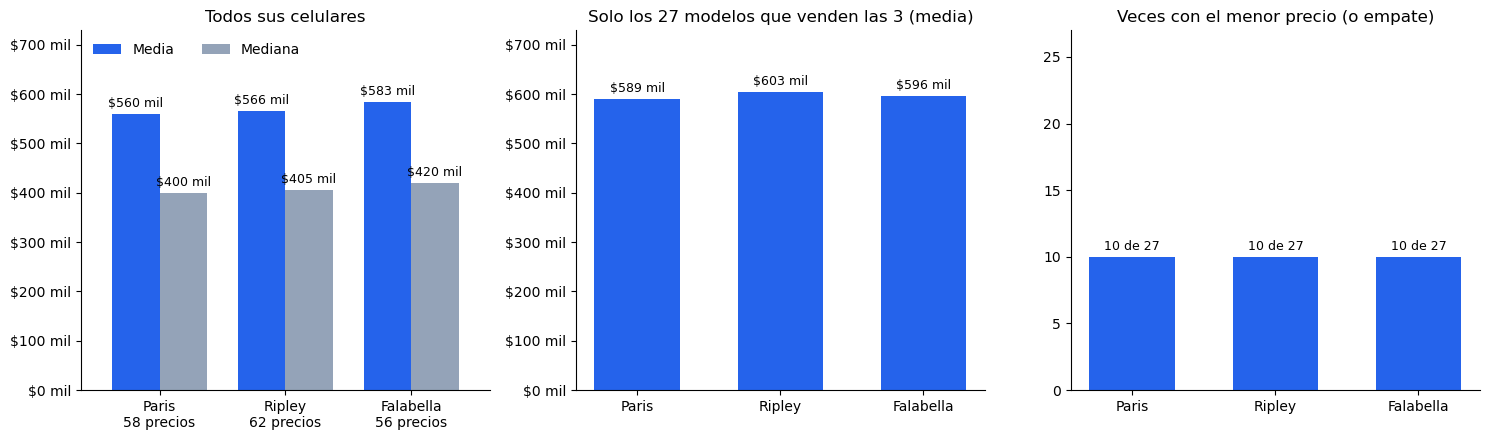

tienda
Paris        589176.0
Falabella    596286.0
Ripley       603323.0
dtype: float64

In [7]:
tres = nuevos[nuevos.tienda.isin(["Ripley", "Falabella", "Paris"])]      # solo esas 3 tiendas, equipos nuevos
res = tres.groupby("tienda").precio_oferta.agg(["mean", "median", "count"]).sort_values("mean")   # resumen por tienda
print(res.round(0))

# Control: cada tienda vende celulares distintos, y eso mueve su promedio. Comparamos solo los modelos que venden las 3.
comun = tres.pivot_table(index="nombre", columns="tienda", values="precio_oferta").dropna()   # 1 fila por modelo, 1 columna por tienda
veces = (comun.rank(axis=1, method="min") == 1).sum()                     # rank 1 = la más barata para ese modelo (o empatada)
print(f"\n{len(comun)} modelos en común | veces que cada tienda tiene el menor precio:", veces.to_dict())

# Gráficos: 3 paneles con las tiendas en el mismo orden (de menor a mayor promedio simple)
orden = res.index
miles = lambda v: f"${v/1e3:,.0f} mil".replace(",", ".")                  # 570481 → $570 mil
fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(15, 4.5))

# Panel 1: media y mediana con TODOS los celulares de cada tienda
res[["mean", "median"]].set_axis(["Media", "Mediana"], axis=1).plot.bar(ax=a1, color=["#2563eb", "#94a3b8"], rot=0, width=0.75)
a1.set_xticks(range(len(orden)), [f"{t}\n{n:.0f} precios" for t, n in res["count"].items()])   # nombre + n° de precios
for cont in a1.containers: a1.bar_label(cont, labels=[miles(v) for v in cont.datavalues], padding=3, fontsize=9)
a1.set_ylim(top=res["mean"].max() * 1.25)                                  # espacio para la leyenda
a1.legend(loc="upper left", ncol=2, frameon=False)
a1.set(title="Todos sus celulares", xlabel="")

# Panel 2: media con SOLO los modelos que venden las 3 (misma escala que el panel 1, para comparar)
a2.bar(orden, comun.mean()[orden], color="#2563eb", width=0.6)
a2.bar_label(a2.containers[0], labels=[miles(v) for v in comun.mean()[orden]], padding=3, fontsize=9)
a2.set_ylim(a1.get_ylim())
a2.set(title=f"Solo los {len(comun)} modelos que venden las 3 (media)")

# Panel 3: en cuántos de esos modelos cada tienda es la más barata
a3.bar(orden, veces[orden], color="#2563eb", width=0.6)
a3.bar_label(a3.containers[0], labels=[f"{v} de {len(comun)}" for v in veces[orden]], padding=3, fontsize=9)
a3.set_ylim(top=len(comun))                                                # eje hasta el total de modelos en común
a3.set(title="Veces con el menor precio (o empate)")

for a in (a1, a2): a.yaxis.set_major_formatter(lambda y, _: miles(y))     # eje en miles de pesos
for a in (a1, a2, a3): a.spines[["top", "right"]].set_visible(False)       # quita bordes que no aportan
plt.tight_layout()
plt.show()

comun.mean().sort_values().round(0)

**Interpretación:**

- **Todos sus celulares** (panel 1): media y mediana de cada tienda, con su cantidad de precios bajo el nombre. Paris tiene la media y la mediana más bajas (\$560.042 y \$399.990), y Falabella, las más altas (\$583.329 y \$419.990). En las tres, la media supera a la mediana por ~\$160 mil: pocos equipos muy caros inflan el promedio.

- **Ofertas no es lo mismo que modelos:** el número bajo cada tienda cuenta **precios** (ofertas), no modelos. Falabella y Ripley tienen una oferta por modelo (56 y 62). Paris tiene **58 ofertas de 57 modelos**, porque publica dos veces el Vivo X500 Pro Max, a \$1.899.990 y \$1.999.990. En el promedio simple ese modelo pesa doble; en el panel 2 entra con el promedio de sus dos precios, un valor por modelo.

- **Solo los 27 modelos en común** (panel 2): compara el mismo celular en las tres tiendas. Paris sigue siendo la más barata (\$589.176), pero entre las otras dos el orden se invierte: Falabella (\$596.286) queda bajo Ripley (\$603.323). Tiene la misma escala que el panel 1, así que las alturas se comparan directo.

- **Veces con el menor precio** (panel 3): cada tienda tiene el menor precio, o empata, en **10 de los 27 modelos**. Ninguna es sistemáticamente la más barata.

Los tres paneles suman 30 y no 27 porque, cuando dos tiendas empatan en el precio más bajo, el modelo cuenta para ambas. Por eso el título dice "(o empate)".

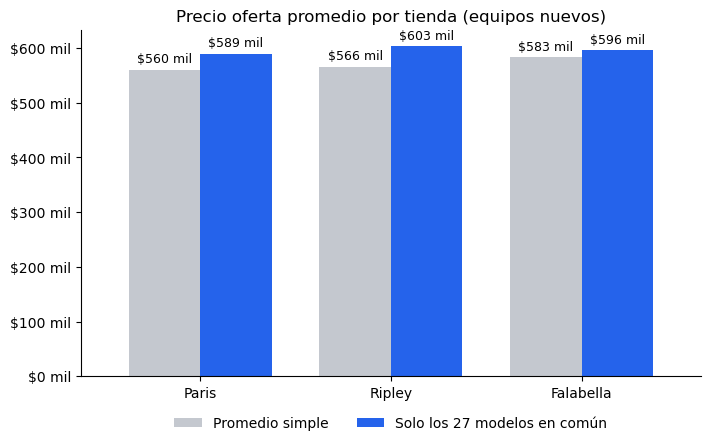

In [8]:
comp = pd.DataFrame({"Promedio simple": tres.groupby("tienda").precio_oferta.mean(),
                     f"Solo los {len(comun)} modelos en común": comun.mean()}).sort_values("Promedio simple")
ax = comp.plot.bar(color=["#c4c8cf", "#2563eb"], figsize=(8, 4.5), width=0.75, rot=0)
for cont in ax.containers:                                                 # monto sobre cada barra
    ax.bar_label(cont, labels=[f"${v/1e3:,.0f} mil".replace(",", ".") for v in cont.datavalues], padding=3, fontsize=9)
ax.set(title="Precio oferta promedio por tienda (equipos nuevos)", xlabel="", ylabel="")
ax.yaxis.set_major_formatter(lambda y, _: f"${y/1e3:,.0f} mil".replace(",", "."))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2, frameon=False)   # leyenda bajo el gráfico, sin tapar barras
ax.spines[["top", "right"]].set_visible(False)
plt.show()

#### Conclusión de la pregunta B

**Interpretación:**

- **Promedio simple:** **Paris es la más barata (\$560.042)** y **Falabella la más cara (\$583.329)**, con Ripley al medio (\$566.200). La brecha entre los extremos es de \$23.287 (4,2%).

- **El promedio simple compara catálogos distintos** (57, 56 y 62 modelos), por eso se controla con los mismos celulares.

- **Control con los mismos celulares:** en los **27 modelos que venden las tres tiendas**, Paris sigue primera (\$589.176), pero la más cara pasa a ser **Ripley** (\$603.323), con Falabella al medio (\$596.286). La brecha baja a 2,4% (≈ \$14 mil), y cada tienda tiene el menor precio en 10 de los 27 modelos.

- **Conclusión:**
  - **Paris es la más barata con ambos métodos**, pero por poco: ~1,2% menos que la siguiente para un mismo celular, y no en todos los modelos.
  - **Cuál es la más cara depende del método:** Falabella con el promedio simple, Ripley con los mismos modelos. Con los mismos modelos, la diferencia entre ambas es ~1%, así que ninguna es claramente la más cara.
  - Parte de la brecha del promedio simple (4,2% contra 2,4%) viene de **qué celulares vende cada tienda**, no del precio de un mismo equipo.
  - Para la emprendedora: para un mismo celular, las tres multitiendas cobran precios muy parecidos. Paris es una referencia levemente más agresiva.

### Pregunta C: Modelos únicos por marca
Muestra cuántos modelos de celular únicos ofrece cada marca en el mercado (sin contar el mismo modelo vendido en diferentes tiendas). Presenta esta información en un gráfico de barras ordenado de mayor a menor. Haz una pequeña interpretación.

242 modelos en el catálogo de 16 marcas | por tipo: {'Se vende nuevo': 195, 'Solo reacondicionado o usado': 37, 'Sin oferta liberada (solo con plan o sin ofertas)': 10}


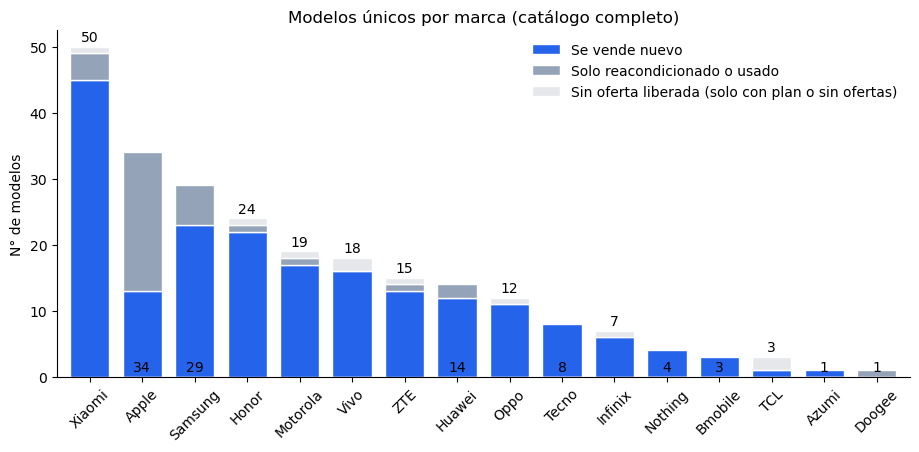

tipo,Se vende nuevo,Solo reacondicionado o usado,Sin oferta liberada (solo con plan o sin ofertas),Total
marca,,,,
Xiaomi,45,4,1,50
Apple,13,21,0,34
Samsung,23,6,0,29
Honor,22,1,1,24
Motorola,17,1,1,19
Vivo,16,0,2,18
ZTE,13,1,1,15
Huawei,12,2,0,14
Oppo,11,0,1,12


In [9]:
# Catálogo completo: cada celular cuenta una vez, se venda nuevo, solo reacondicionado/usado o sin oferta liberada
estado = clean.groupby("nombre").agg(marca=("marca", "first"), nuevo=("es_nuevo", "max"), disp=("disponibilidad", "first"))
estado["tipo"] = estado.nuevo.map({1: "Se vende nuevo", 0: "Solo reacondicionado o usado"}).fillna("Sin oferta liberada (solo con plan o sin ofertas)")
tabla = pd.crosstab(estado.marca, estado.tipo)                             # n° de modelos por marca y tipo
tabla = tabla.loc[tabla.sum(axis=1).sort_values(ascending=False).index]    # marcas de mayor a menor
tabla = tabla[[c for c in ["Se vende nuevo", "Solo reacondicionado o usado", "Sin oferta liberada (solo con plan o sin ofertas)"] if c in tabla]]
print(f"{len(estado)} modelos en el catálogo de {estado.marca.nunique()} marcas | por tipo:", estado.tipo.value_counts().to_dict())

ax = tabla.plot.bar(stacked=True, figsize=(11, 4.5), color=["#2563eb", "#94a3b8", "#e5e7eb"], width=0.75, rot=45, edgecolor="white")
ax.bar_label(ax.containers[-1], labels=tabla.sum(axis=1), padding=2)       # total de modelos sobre cada barra
ax.set(title="Modelos únicos por marca (catálogo completo)", ylabel="N° de modelos", xlabel="")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()
tabla.assign(Total=tabla.sum(axis=1))                                      # la tabla se muestra debajo del gráfico

#### Conclusión de la pregunta C

**Interpretación:**

- El catálogo tiene **242 modelos de 16 marcas**. **Xiaomi lidera con 50**, seguida de Apple (34) y Samsung (29). Esas 3 marcas suman el **47%** de los modelos; con Honor (24) y Motorola (19), las 5 primeras llegan al **64%**.

- **Cola larga:** Bmobile y TCL tienen 3 modelos, y Azumi y Doogee, uno cada una.

- **Se cuenta el catálogo completo**, como solicita en el enunciado: 195 modelos se venden nuevos, 37 solo reacondicionados o usados, y 10 no tienen oferta liberada (9 se venden solo con plan y 1 no tiene ofertas). Los colores del gráfico separan esos tres grupos.

- **Matiz de Apple:** de sus 34 modelos, solo 13 se venden nuevos; los otros 21 son iPhone de generaciones anteriores que solo se ofrecen reacondicionados o usados. Esto revela una oferta de segunda mano relevante. Xiaomi, en cambio, vende 45 de sus 50 modelos nuevos.

- Cada "modelo" es una variante (nombre del producto), tal como pide el enunciado.

- **Lectura para la emprendedora:** el catálogo observado concentra buena parte de sus modelos en pocas marcas. Contar modelos no mide ventas ni participación de mercado: muestra la **amplitud de la oferta** de cada marca. Xiaomi tiene la oferta más amplia, con variantes en todos los rangos de precio. Para una marca nueva, competir por amplitud de catálogo exigiría decenas de variantes; un portafolio corto, enfocado en el tramo de precio donde su relación características/precio sea mejor, es más abordable.

## Otros análisis exploratorios

In [10]:
m = clean.drop_duplicates("nombre")                                       # 1 fila por modelo: cada celular cuenta una vez
ofertas = clean.dropna(subset=["precio_oferta"]).nombre.value_counts()    # n° de ofertas liberadas (tienda + condición) de cada modelo
print(f"{len(m)} modelos únicos | {ofertas.sum()} ofertas | ofertas por modelo: mediana {ofertas.median():.0f}, máximo {ofertas.max()}")

# Marcas: las 6 con más modelos tienen color propio; el resto se agrupa en "Otras" (más de 7 colores no se distinguen)
top6 = list(m.marca.value_counts().index[:6])
marca7 = m.marca.where(m.marca.isin(top6), "Otras").rename("Marca")
colores = dict(zip(top6 + ["Otras"], ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#56B4E9", "#CC79A7", "#c4c8cf"]))   # apta para daltonismo

# Agrupa una columna numérica en tramos [desde, hasta)
tramo = lambda col, cortes, etiquetas: pd.cut(m[col], cortes, labels=etiquetas, right=False)

def barras(s, titulo, rot=0):                                             # barras simples con n° y % de los modelos
    ax = s.plot.bar(figsize=(9, 4.5), color="#2563eb", width=0.75, rot=rot)
    ax.bar_label(ax.containers[0], labels=[f"{v}\n{v/len(m):.0%}" for v in s], padding=2, fontsize=9)
    ax.set_ylim(top=s.max() * 1.25)                                       # espacio para las etiquetas
    ax.set(title=titulo, xlabel="", ylabel="N° de modelos")
    ax.spines[["top", "right"]].set_visible(False)
    plt.show()

def barras_marca(grupo, titulo):                                          # barras apiladas: cada segmento es una marca
    t = pd.crosstab(grupo, marca7)[top6 + ["Otras"]]                      # filas: tramos; columnas: marcas (n° de modelos)
    ax = t.plot.bar(stacked=True, figsize=(10, 5), color=colores, width=0.75, rot=0, edgecolor="white", linewidth=1)
    ax.bar_label(ax.containers[-1], labels=[f"{v}\n{v/len(m):.0%}" for v in t.sum(axis=1)], padding=2, fontsize=9)   # total arriba
    ax.set_ylim(top=t.sum(axis=1).max() * 1.25)
    ax.set(title=titulo, xlabel="", ylabel="N° de modelos")
    ax.legend(title="Marca", loc="upper left", bbox_to_anchor=(1, 1), frameon=False)   # leyenda fuera del gráfico, a la derecha
    ax.spines[["top", "right"]].set_visible(False)
    plt.show()
    return t                                                              # la tabla se muestra debajo del gráfico

242 modelos únicos | 996 ofertas | ofertas por modelo: mediana 2, máximo 22


### Ofertas por modelo (Top 15)

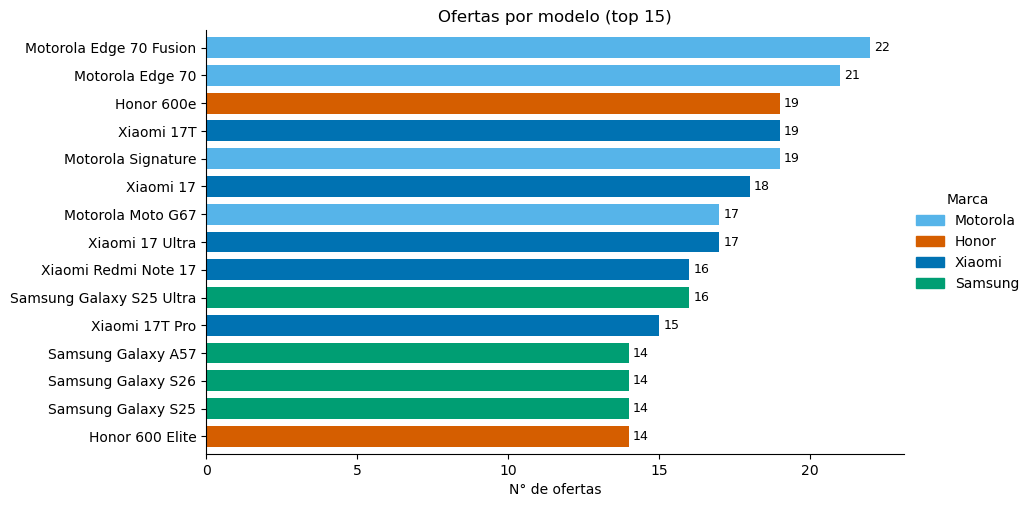

In [11]:
m7 = pd.Series(marca7.values, index=m.nombre)                            # marca (o "Otras") de cada modelo
top = ofertas.head(15)                                                    # 15 modelos con más ofertas
ax = top.rename(lambda n: n.split(" (")[0])[::-1].plot.barh(              # nombre sin la variante; el mayor arriba
    figsize=(9, 5.5), width=0.75, color=[colores[m7[n]] for n in top.index[::-1]])   # cada barra con el color de su marca
ax.bar_label(ax.containers[0], padding=3, fontsize=9)
marcas = list(m7[top.index].unique())                                     # marcas presentes en el top 15
ax.legend([plt.Rectangle((0, 0), 1, 1, color=colores[b]) for b in marcas], marcas,
          title="Marca", loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
ax.set(title="Ofertas por modelo (top 15)", xlabel="N° de ofertas", ylabel="")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

### Modelos con más ofertas por marca (Top 3)

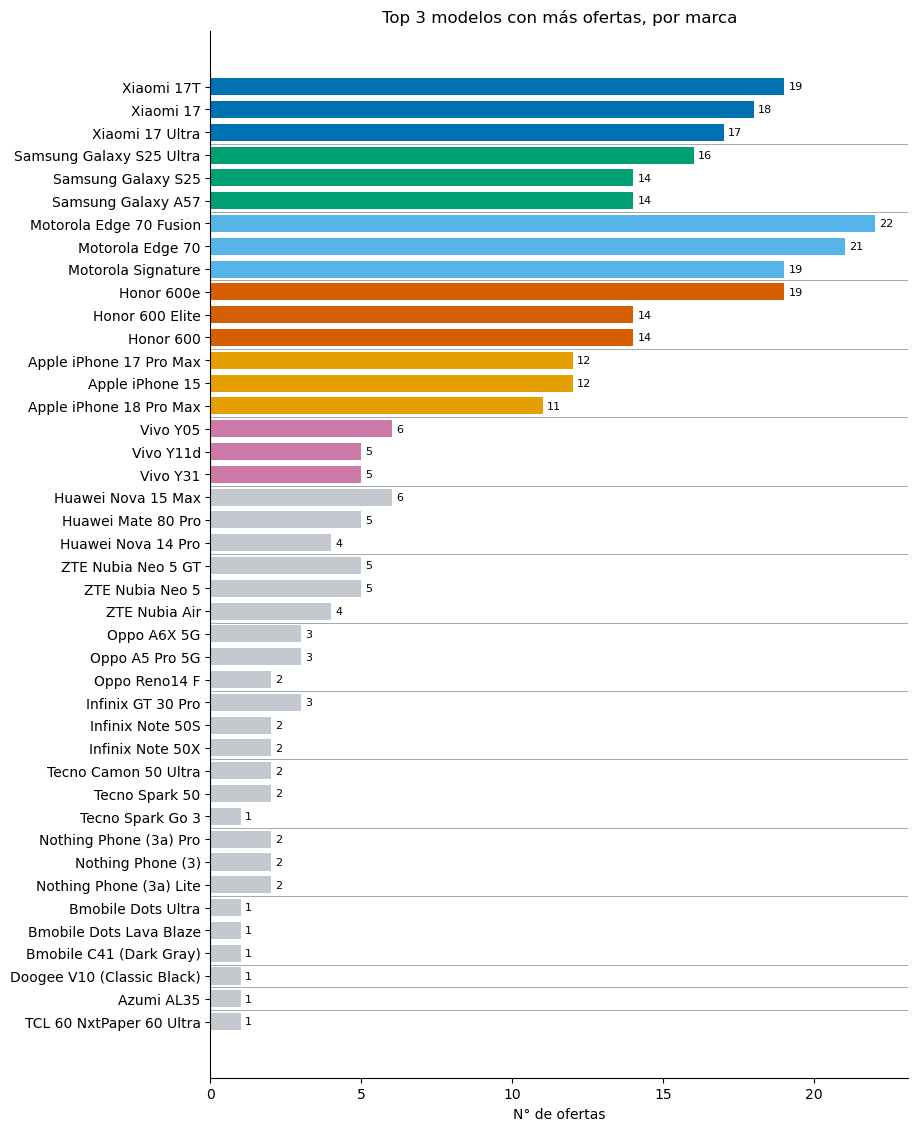

In [12]:
con_oferta = clean.dropna(subset=["precio_oferta"])                       # solo filas con oferta liberada
d = (con_oferta.groupby(["marca", "nombre"]).size().rename("ofertas").reset_index()     # ofertas por modelo
       .sort_values("ofertas", ascending=False).groupby("marca").head(3))           # top 3 modelos de cada marca
d["total_marca"] = d.marca.map(con_oferta.marca.value_counts())                          # ofertas totales de la marca (para ordenar)
d = d.sort_values(["total_marca", "ofertas"], ascending=False)                       # marcas de mayor a menor; dentro, modelos de mayor a menor
d["modelo"] = d.nombre.str.replace(r" \([^()]*GB.*$", "", regex=True)               # quita la variante "(256 GB / …)"

fig, ax = plt.subplots(figsize=(9, 0.3 * len(d) + 1))                              # alto según el n° de barras
ax.barh(range(len(d)), d.ofertas, color=d.marca.map(colores).fillna("#c4c8cf"), height=0.75)   # color de la marca (gris = "Otras")
ax.set_yticks(range(len(d)), d.modelo)
ax.invert_yaxis()                                                                    # la primera marca arriba
ax.bar_label(ax.containers[0], padding=3, fontsize=8)
for y in (d.marca != d.marca.shift()).to_numpy().nonzero()[0][1:]:                  # línea divisoria donde cambia la marca
    ax.axhline(y - 0.5, color="#999", linewidth=0.6)
ax.set(title="Top 3 modelos con más ofertas, por marca", xlabel="N° de ofertas", ylabel="")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

### Modelos por pantalla según marca

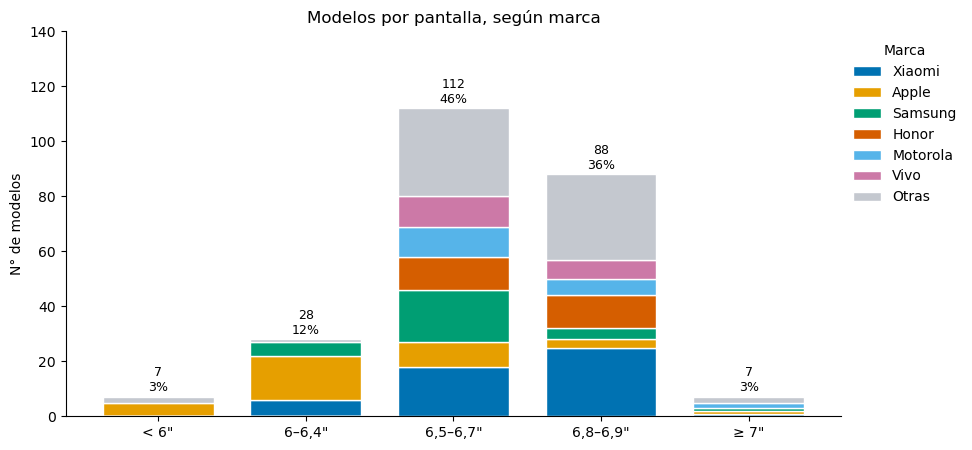

Marca,Xiaomi,Apple,Samsung,Honor,Motorola,Vivo,Otras
pantalla_pulg,,,,,,,
"< 6""",0,5,0,0,0,0,2
"6–6,4""",6,16,5,0,0,0,1
"6,5–6,7""",18,9,19,12,11,11,32
"6,8–6,9""",25,3,4,12,6,7,31
"≥ 7""",1,1,1,0,2,0,2


In [13]:
barras_marca(tramo("pantalla_pulg", [0, 6, 6.5, 6.8, 7, 99], ['< 6"', '6–6,4"', '6,5–6,7"', '6,8–6,9"', '≥ 7"']), "Modelos por pantalla, según marca")

### Modelos por peso según marca

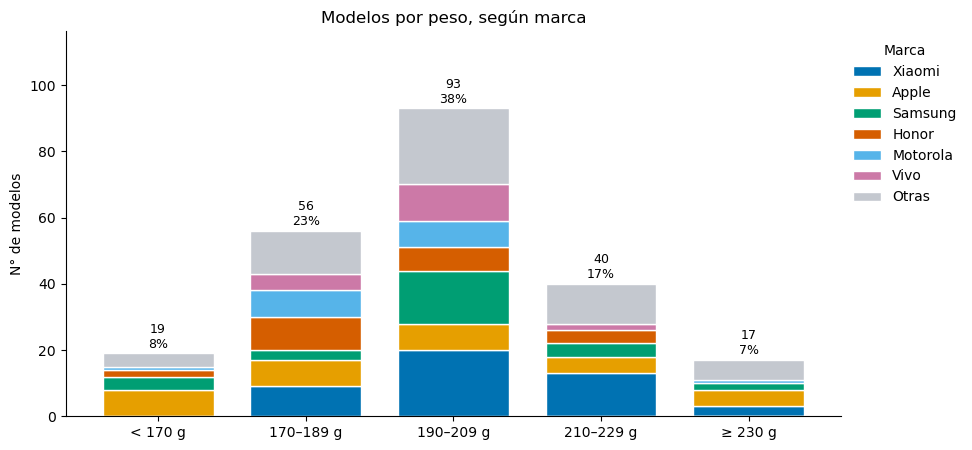

Marca,Xiaomi,Apple,Samsung,Honor,Motorola,Vivo,Otras
peso_g,,,,,,,
< 170 g,0,8,4,2,1,0,4
170–189 g,9,8,3,10,8,5,13
190–209 g,20,8,16,7,8,11,23
210–229 g,13,5,4,4,0,2,12
≥ 230 g,3,5,2,0,1,0,6


In [14]:
barras_marca(tramo("peso_g", [0, 170, 190, 210, 230, 999], ["< 170 g", "170–189 g", "190–209 g", "210–229 g", "≥ 230 g"]), "Modelos por peso, según marca")

### Modelos por RAM según marca

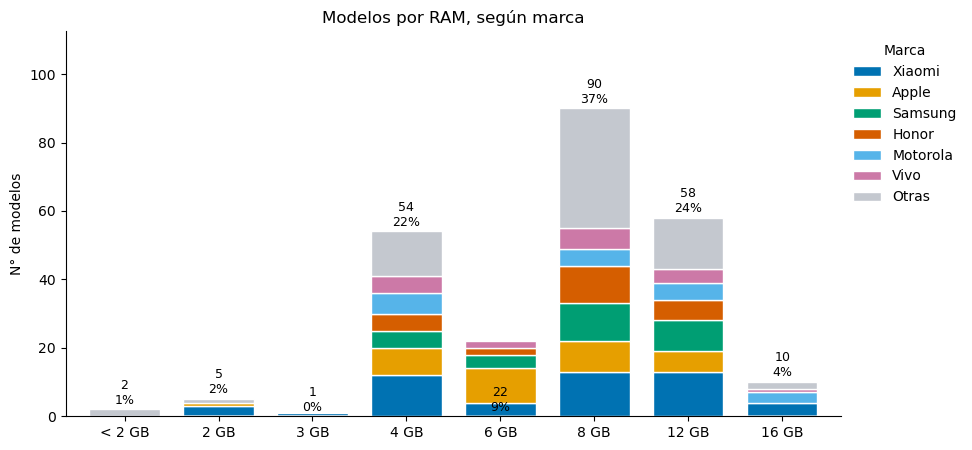

Marca,Xiaomi,Apple,Samsung,Honor,Motorola,Vivo,Otras
ram_gb,,,,,,,
< 2 GB,0,0,0,0,0,0,2
2 GB,3,1,0,0,0,0,1
3 GB,1,0,0,0,0,0,0
4 GB,12,8,5,5,6,5,13
6 GB,4,10,4,2,0,2,0
8 GB,13,9,11,11,5,6,35
12 GB,13,6,9,6,5,4,15
16 GB,4,0,0,0,3,1,2


In [15]:
barras_marca(tramo("ram_gb", [0, 2, 3, 4, 6, 8, 12, 16, 99], ["< 2 GB", "2 GB", "3 GB", "4 GB", "6 GB", "8 GB", "12 GB", "16 GB"]), "Modelos por RAM, según marca")

### Modelos por cámara principal (suma MP) según marca

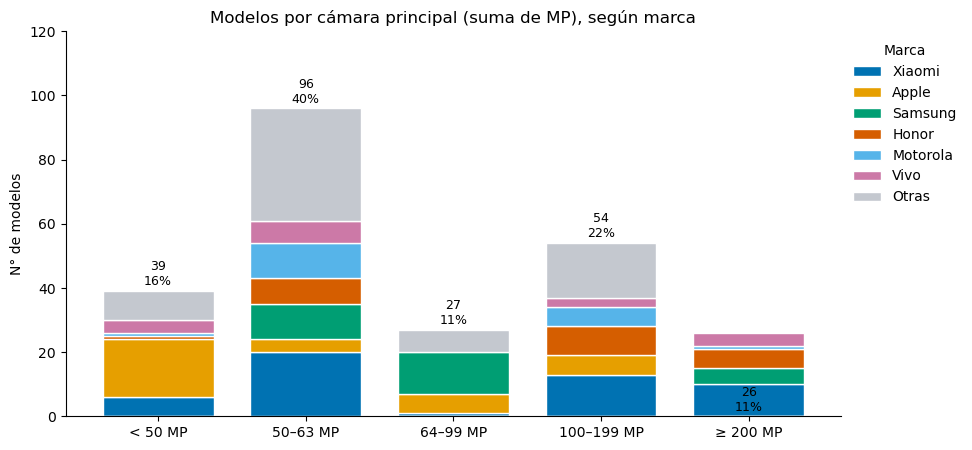

Marca,Xiaomi,Apple,Samsung,Honor,Motorola,Vivo,Otras
camara_principal_mp,,,,,,,
< 50 MP,6,18,0,1,1,4,9
50–63 MP,20,4,11,8,11,7,35
64–99 MP,1,6,13,0,0,0,7
100–199 MP,13,6,0,9,6,3,17
≥ 200 MP,10,0,5,6,1,4,0


In [16]:
barras_marca(tramo("camara_principal_mp", [0, 50, 64, 100, 200, 999], ["< 50 MP", "50–63 MP", "64–99 MP", "100–199 MP", "≥ 200 MP"]), "Modelos por cámara principal (suma de MP), según marca")